### Notebook 04 — HDBSCAN Regional Clustering

**Question:** do declining cells form a real region, or are they isolated noisy squares?

Pipeline so far: `cleaned AIS → monthly cells (nb02) → annual cells + trends (nb03: 8,697 cells, 557 with ≥5 years, 7 Declining)`. Single-cell `p < 0.05` cannot define a region (expect ~28 false positives at 557 tests).

This notebook groups trend-eligible cells with **HDBSCAN** (not KMeans/DBSCAN-with-one-eps): no `k` to guess, arbitrary coastal shapes, varying inshore/offshore density, and noise (`label=-1`) as first-class for the 8,140 sparse cells.

Two views:
1. **Spatial HDBSCAN** on projected km coords — are decliners adjacent?
2. **Feature HDBSCAN** on standardized trend features — do decliners share trajectory shape?

A region = spatial cluster + shared trend direction + vessel diagnostic, not one cell.

### 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import hdbscan
from importlib.metadata import version as _pkg_version
print("hdbscan:", _pkg_version("hdbscan"))

BASE_DIR = Path("..")
ANALYSIS_DIR = BASE_DIR / "outputs" / "analysis"
FIG_DIR = BASE_DIR / "outputs" / "figures" / "nb04"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TREND_PATH = ANALYSIS_DIR / "cell_effort_trends.parquet"
ANNUAL_PATH = ANALYSIS_DIR / "annual_cell_effort_2015_2024.parquet"
print("trends exists:", TREND_PATH.exists())
print("annual exists:", ANNUAL_PATH.exists())

MIN_YEARS = 5  # same as nb03 section 7


hdbscan: 0.8.44
trends exists: True
annual exists: True


### 2. Load trend + annual tables

In [2]:
trends = pd.read_parquet(TREND_PATH)
annual = pd.read_parquet(ANNUAL_PATH)
print("trends:", trends.shape)
print(trends["trend_class"].value_counts())
print("annual:", annual.shape)

eligible = trends[trends["n_years"] >= MIN_YEARS].copy().reset_index(drop=True)
print(f"eligible (n_years >= {MIN_YEARS}):", len(eligible))
print("declining among eligible:", int((eligible["trend_class"] == "Declining").sum()))
display(eligible.head())


trends: (8697, 16)
trend_class
Insufficient data           8140
Stable / not significant     511
Increasing                    39
Declining                      7
Name: count, dtype: int64
annual: (19730, 12)
eligible (n_years >= 5): 557
declining among eligible: 7


,cell_ll_lat,cell_ll_lon,n_years,slope_hours_per_year,intercept,r_squared,regression_p_value,spearman_rho,spearman_p_value,first_year,last_year,first_effort,last_effort,absolute_change_hours,percent_change,trend_class
0,8.0,75.1,5.0,-0.064320,144.633579,0.000125,0.985740,0.100000,8.728886e-01,2019.0,2024.0,6.390800,6.716071,0.325271,5.089682,Stable / not significant
1,8.0,77.0,5.0,9.370767,-18922.180204,0.927512,0.008471,1.000000,1.404265e-24,2020.0,2024.0,10.099400,42.547675,32.448275,321.289136,Increasing
2,8.0,77.1,6.0,8.781599,-17727.053707,0.772448,0.021113,0.885714,1.884548e-02,2019.0,2024.0,8.513275,57.458483,48.945208,574.928078,Increasing
3,8.0,77.2,6.0,5.253248,-10606.548215,0.841333,0.009990,0.885714,1.884548e-02,2019.0,2024.0,0.784200,23.004175,22.219975,2833.457664,Increasing
4,8.1,76.8,5.0,12.233833,-24684.483409,0.270251,0.369255,0.500000,3.910022e-01,2020.0,2024.0,0.207733,63.556382,63.348648,30495.177384,Stable / not significant


### 3. Project lat/lon to km (degrees distort distance)

In [3]:
# Equirectangular projection around the eligible mean latitude.
# x = lon * cos(mean_lat) * 111.32 km/deg, y = lat * 110.57 km/deg.
# Caveat: fine for a regional (~100s km) view; use proper UTM/haversine for exact distances.
mean_lat = float(eligible["cell_ll_lat"].mean())
kx = float(np.cos(np.radians(mean_lat)) * 111.32)
ky = 110.57
eligible["x_km"] = eligible["cell_ll_lon"] * kx
eligible["y_km"] = eligible["cell_ll_lat"] * ky
print(f"mean_lat={mean_lat:.2f}, kx={kx:.2f} km/deg, ky={ky:.2f} km/deg")
X_spatial = eligible[["x_km", "y_km"]].to_numpy(dtype=float)
print("X_spatial:", X_spatial.shape)


mean_lat=16.10, kx=106.95 km/deg, ky=110.57 km/deg
X_spatial: (557, 2)


### 4. Spatial HDBSCAN (primary: does decline cluster in space?)

In [4]:
# Sweep min_cluster_size: small values fragment the coast, large values melt everything to noise.
# min_samples=None defaults to min_cluster_size (conservative, fewer micro-clusters).
sweep = {}
for mcs in [3, 4, 5, 8]:
    cl = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=None, metric="euclidean")
    lab = cl.fit_predict(X_spatial)
    n_cl = int((pd.Series(lab).value_counts().drop(index=-1, errors="ignore") > 0).sum())
    n_noise = int((lab == -1).sum())
    sweep[mcs] = (lab, n_cl, n_noise)
    print(f"min_cluster_size={mcs}: clusters={n_cl}, noise={n_noise}/{len(lab)}")

BEST_MCS = 4  # change after inspecting the sweep above
spatial_labels = sweep[BEST_MCS][0]
eligible["spatial_cluster"] = spatial_labels
print("chosen:", BEST_MCS, "declining labels:",
      eligible.loc[eligible["trend_class"] == "Declining", "spatial_cluster"].tolist())


min_cluster_size=3: clusters=12, noise=89/557
min_cluster_size=4: clusters=7, noise=15/557
min_cluster_size=5: clusters=5, noise=5/557
min_cluster_size=8: clusters=4, noise=11/557
chosen: 4 declining labels: [6, 6, 6, 6, 6, 6, 6]


### 5. Feature HDBSCAN (do decliners share trajectory shape?)

In [5]:
# Features per eligible cell: slope (clipped to 1/99 pct to tame extremes like +63),
# log mean effort level, and n_years (data support). Standardized before HDBSCAN.
# Missing slopes (should be none among eligible) are dropped from this view only.
feat = eligible.copy()
feat["mean_effort"] = (feat["first_effort"] + feat["last_effort"]).replace([np.inf, -np.inf], np.nan) / 2
feat = feat.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["slope_hours_per_year", "mean_effort", "n_years"]).reset_index(drop=True)
lo, hi = feat["slope_hours_per_year"].quantile([0.01, 0.99])
feat["slope_clip"] = feat["slope_hours_per_year"].clip(lo, hi)
feat["log_effort"] = np.log1p(feat["mean_effort"].clip(lower=0))
Z = StandardScaler().fit_transform(feat[["slope_clip", "log_effort", "n_years"]])
fcl = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=None, metric="euclidean")
feat["feature_cluster"] = fcl.fit_predict(Z)
print(f"slope clip [{lo:.2f}, {hi:.2f}], rows:", len(feat))
print(feat["feature_cluster"].value_counts().head(10))
print("declining feature labels:",
      feat.loc[feat["trend_class"] == "Declining", "feature_cluster"].tolist())


slope clip [-6.88, 68.79], rows: 557
feature_cluster
 1    201
 3    196
 2     79
 0     51
-1     14
 5      9
 4      7
Name: count, dtype: int64
declining feature labels: [0, 1, 3, 1, 1, 3, 3]


### 6. Cluster diagnostics (region test + vessel check)

In [6]:
# A real region: spatial cluster with >=2 declining cells AND shared feature label,
# plus vessel diagnostic from annual (fewer vessels vs same vessels fishing less).
diag = (eligible.groupby("spatial_cluster", as_index=False)
        .agg(n_cells=("cell_ll_lat", "size"),
             n_declining=("trend_class", lambda s: int((s == "Declining").sum())),
             n_increasing=("trend_class", lambda s: int((s == "Increasing").sum())),
             mean_slope=("slope_hours_per_year", "mean")))
display(diag.sort_values(["n_declining", "n_cells"], ascending=False).head(15))

# Vessel check for declining cells specifically (nb03 section 12 fields).
dec_cells = eligible.loc[eligible["trend_class"] == "Declining",
                             ["cell_ll_lat", "cell_ll_lon"]]
dec_annual = annual.merge(dec_cells, on=["cell_ll_lat", "cell_ll_lon"], how="inner")
dec_vessels = (dec_annual.groupby(["cell_ll_lat", "cell_ll_lon"], as_index=False)
               .agg(years=("year", "nunique"),
                    mean_vessels=("active_vessels_unique", "mean"),
                    first_vessels=("active_vessels_unique", "first"),
                    last_vessels=("active_vessels_unique", "last")))
display(dec_vessels)
print("Rule: single declining cell = candidate; >=2 adjacent decliners in one spatial cluster = region candidate.")


,spatial_cluster,n_cells,n_declining,n_increasing,mean_slope
7,6,478,7,35,3.402079
3,2,22,0,4,4.285309
0,-1,15,0,0,5.742804
4,3,14,0,0,56.972259
2,1,12,0,0,1.199110
1,0,6,0,0,0.830700
5,4,5,0,0,-0.678741
6,5,5,0,0,5.928915


,cell_ll_lat,cell_ll_lon,years,mean_vessels,first_vessels,last_vessels
0,17.0,72.8,8,24.125000,15,5
1,17.2,72.5,5,9.800000,20,3
2,18.2,72.5,6,15.833333,21,9
3,18.5,72.0,5,9.800000,18,5
4,18.5,72.4,5,15.800000,26,6
5,18.6,72.3,6,14.000000,20,2
6,18.6,72.4,6,15.000000,17,3


Rule: single declining cell = candidate; >=2 adjacent decliners in one spatial cluster = region candidate.


### 7. Maps

C:\Users\pauls\AppData\Local\Temp\ipykernel_19600\3007119424.py:8: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(eligible.loc[m, "cell_ll_lon"], eligible.loc[m, "cell_ll_lat"],


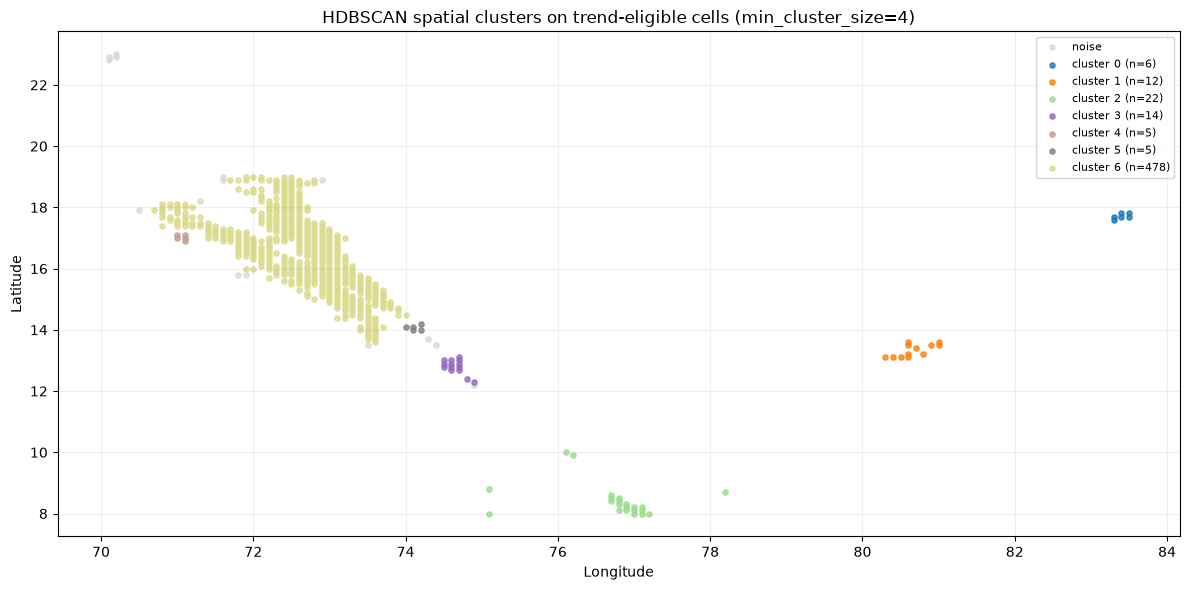

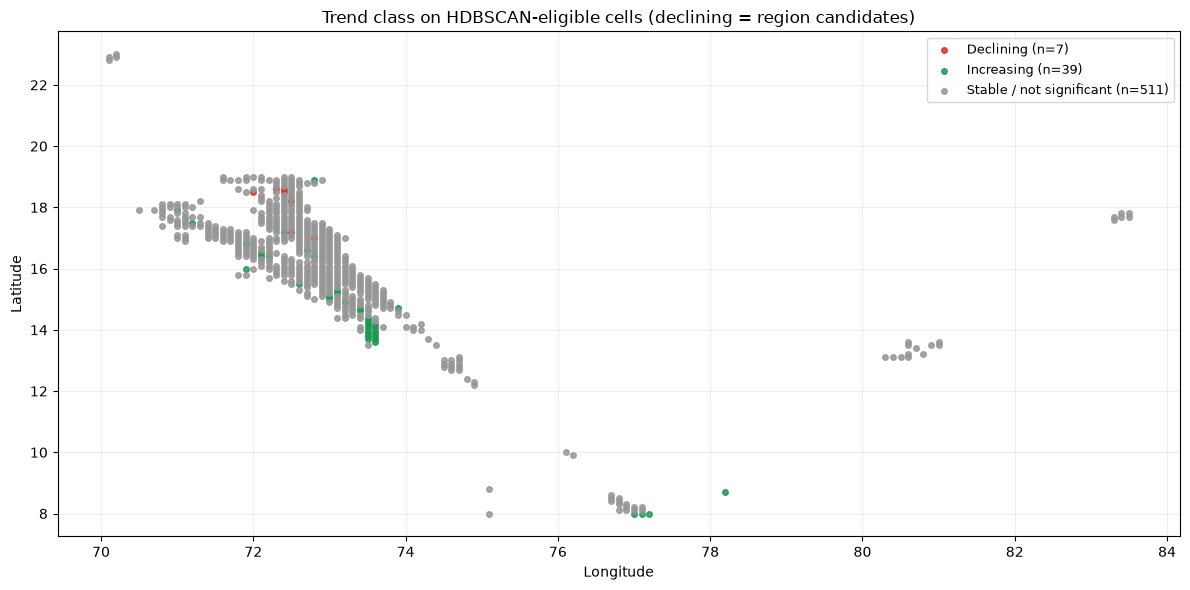

saved to D:\ResearchPapers\AIS_Data_Analysis\outputs\figures\nb04


In [7]:
# Map A: spatial HDBSCAN clusters (noise grey, -1). Map B: trend class overlay.
plt.figure(figsize=(12, 6))
labs = eligible["spatial_cluster"].to_numpy()
uniq = sorted(set(labs))
cmap = plt.get_cmap("tab20", max(len(uniq), 2))
for k in uniq:
    m = labs == k
    plt.scatter(eligible.loc[m, "cell_ll_lon"], eligible.loc[m, "cell_ll_lat"],
                s=14, alpha=0.8, c="#d9d9d9" if k == -1 else cmap(k % 20),
                label=f"noise" if k == -1 else f"cluster {k} (n={(m).sum()})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"HDBSCAN spatial clusters on trend-eligible cells (min_cluster_size={BEST_MCS})")
plt.grid(alpha=0.2)
plt.legend(fontsize=8, loc="best", frameon=True)
plt.tight_layout()
plt.savefig(FIG_DIR / "nb04_spatial_hdbscan_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 6))
pal = {"Declining": "#d73027", "Increasing": "#1a9850", "Stable / not significant": "#969696"}
for cls, grp in eligible.groupby("trend_class"):
    if cls == "Insufficient data":
        continue
    plt.scatter(grp["cell_ll_lon"], grp["cell_ll_lat"], s=16, alpha=0.85,
                c=pal.get(cls, "#969696"), label=f"{cls} (n={len(grp)})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Trend class on HDBSCAN-eligible cells (declining = region candidates)")
plt.grid(alpha=0.2)
plt.legend(fontsize=9, loc="best", frameon=True)
plt.tight_layout()
plt.savefig(FIG_DIR / "nb04_trend_overlay.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved to", FIG_DIR.resolve())


### 8. Export

In [8]:
eligible.to_parquet(ANALYSIS_DIR / "hdbscan_spatial_clusters.parquet", index=False)
feat[["cell_ll_lat", "cell_ll_lon", "feature_cluster"]].to_parquet(
    ANALYSIS_DIR / "hdbscan_feature_clusters.parquet", index=False)
print("saved:", ANALYSIS_DIR / "hdbscan_spatial_clusters.parquet")
print("saved:", ANALYSIS_DIR / "hdbscan_feature_clusters.parquet")


saved: ..\outputs\analysis\hdbscan_spatial_clusters.parquet
saved: ..\outputs\analysis\hdbscan_feature_clusters.parquet


### 9. Clusters on an actual India map

Same HDBSCAN results as Section 7, now drawn over a real coastline (Natural Earth 110m, `outputs/geo/ne_110m_admin_0_countries.geojson`, India + neighbours for context). No new dependencies — plain `matplotlib` polygons.

Coastline is coarse (110m); cells hugging the shore can look on-land. For exact claims use 10m/50m Natural Earth or GADM.


coastline patches: 7


C:\Users\pauls\AppData\Local\Temp\ipykernel_19600\3021823639.py:42: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(eligible.loc[m, "cell_ll_lon"], eligible.loc[m, "cell_ll_lat"],


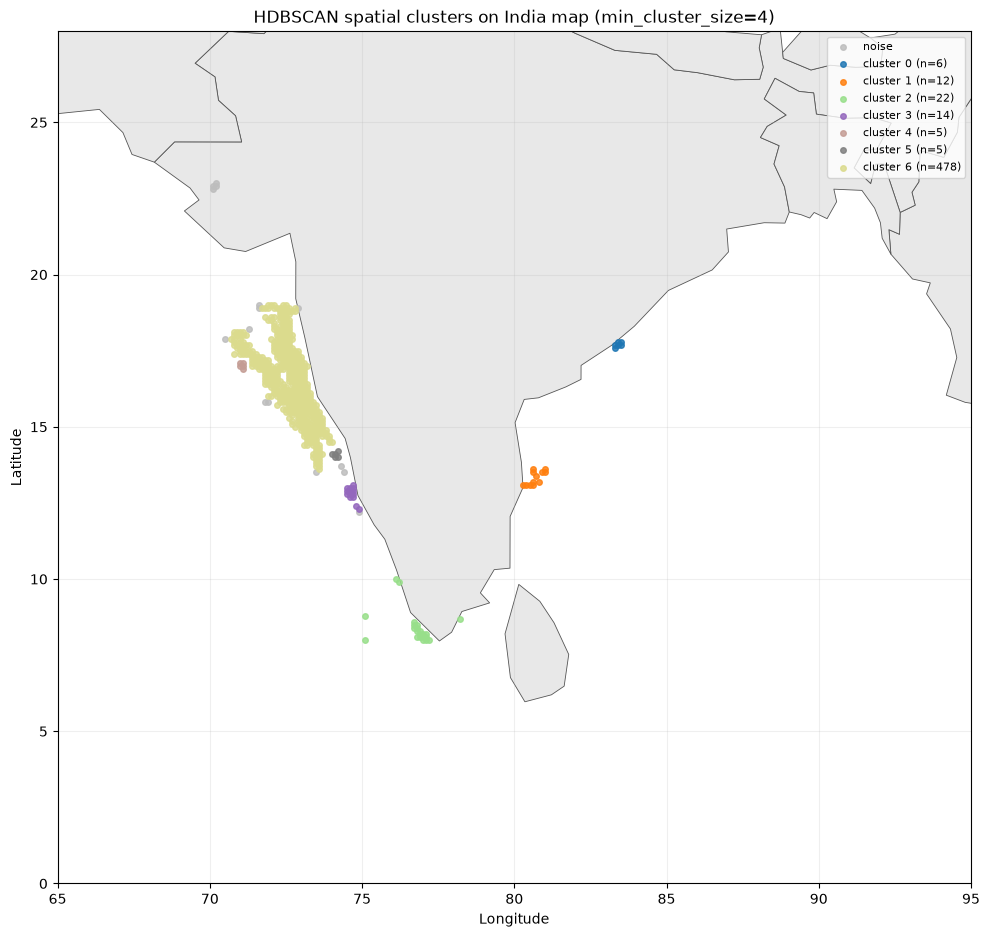

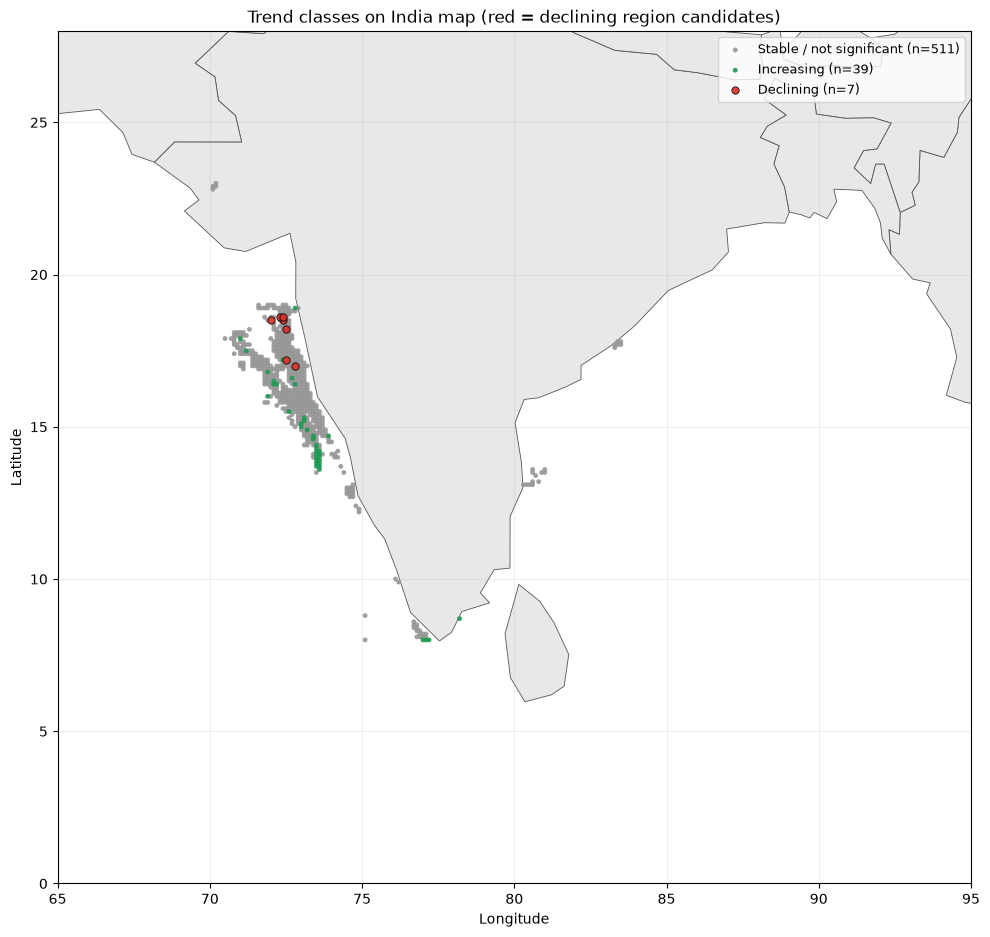

saved to D:\ResearchPapers\AIS_Data_Analysis\outputs\figures\nb04


In [9]:
import json
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

GEO_PATH = BASE_DIR / "outputs" / "geo" / "ne_110m_admin_0_countries.geojson"
gj = json.load(open(GEO_PATH, encoding="utf-8"))

def _polys(feature):
    g = feature["geometry"]
    if g["type"] == "Polygon":
        yield g["coordinates"]
    elif g["type"] == "MultiPolygon":
        for poly in g["coordinates"]:
            yield poly

WANT = {"India", "Pakistan", "Bangladesh", "Myanmar", "Sri Lanka", "Nepal", "Bhutan"}
coast = []
for f in gj["features"]:
    nm = f["properties"].get("ADMIN") or f["properties"].get("NAME")
    if nm in WANT:
        for poly in _polys(f):
            coast.append(Polygon(poly[0], closed=True))
print(f"coastline patches: {len(coast)}")

def india_axes(ax):
    ax.add_collection(PatchCollection(coast, facecolor="#e8e8e8", edgecolor="#555555", linewidths=0.6, zorder=1))
    ax.set_xlim(65, 95)
    ax.set_ylim(0, 28)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.2)

# Map C: spatial HDBSCAN clusters on India coastline
fig, ax = plt.subplots(figsize=(10, 10))
india_axes(ax)
labs = eligible["spatial_cluster"].to_numpy()
uniq = sorted(set(labs))
cmap = plt.get_cmap("tab20", max(len(uniq), 2))
for k in uniq:
    m = labs == k
    ax.scatter(eligible.loc[m, "cell_ll_lon"], eligible.loc[m, "cell_ll_lat"],
               s=16, alpha=0.85, c="#bdbdbd" if k == -1 else cmap(k % 20),
               label=f"noise" if k == -1 else f"cluster {k} (n={(m).sum()})", zorder=3)
ax.set_title(f"HDBSCAN spatial clusters on India map (min_cluster_size={BEST_MCS})")
ax.legend(fontsize=8, loc="best", frameon=True)
fig.tight_layout()
fig.savefig(FIG_DIR / "nb04_spatial_clusters_india_map.png", dpi=200, bbox_inches="tight")
plt.show()

# Map D: trend classes on India coastline (decliners on top with black edge)
fig, ax = plt.subplots(figsize=(10, 10))
india_axes(ax)
pal = {"Declining": "#d73027", "Increasing": "#1a9850", "Stable / not significant": "#969696"}
for cls in ["Stable / not significant", "Increasing", "Declining"]:
    grp = eligible[eligible["trend_class"] == cls]
    if grp.empty:
        continue
    edge = "black" if cls == "Declining" else "none"
    ax.scatter(grp["cell_ll_lon"], grp["cell_ll_lat"], s=28 if cls == "Declining" else 12,
               alpha=0.9, c=pal[cls], edgecolors=edge, linewidths=0.6 if cls == "Declining" else 0,
               label=f"{cls} (n={len(grp)})", zorder=4 if cls == "Declining" else 3)
ax.set_title("Trend classes on India map (red = declining region candidates)")
ax.legend(fontsize=9, loc="best", frameon=True)
fig.tight_layout()
fig.savefig(FIG_DIR / "nb04_trend_overlay_india_map.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved to", FIG_DIR.resolve())


### 10. January 2024 monthly snapshot (HDBSCAN on India map)

Same method as Section 4 but on one month: `monthly_cell` for 2024-01 inside the India window (lon 65-95, lat 0-28), projected to km, `HDBSCAN(min_cluster_size=20)`. Point size scales with `fishing_hours`. `mcs=20` is used because `mcs=10` fragments this dense slice into 26 clusters (see sweep in `tools/plot_hdbscan_jan2024.py`).


jan 2024-01 rows (all): 4247
in India window: 3922
clusters=5, noise=122


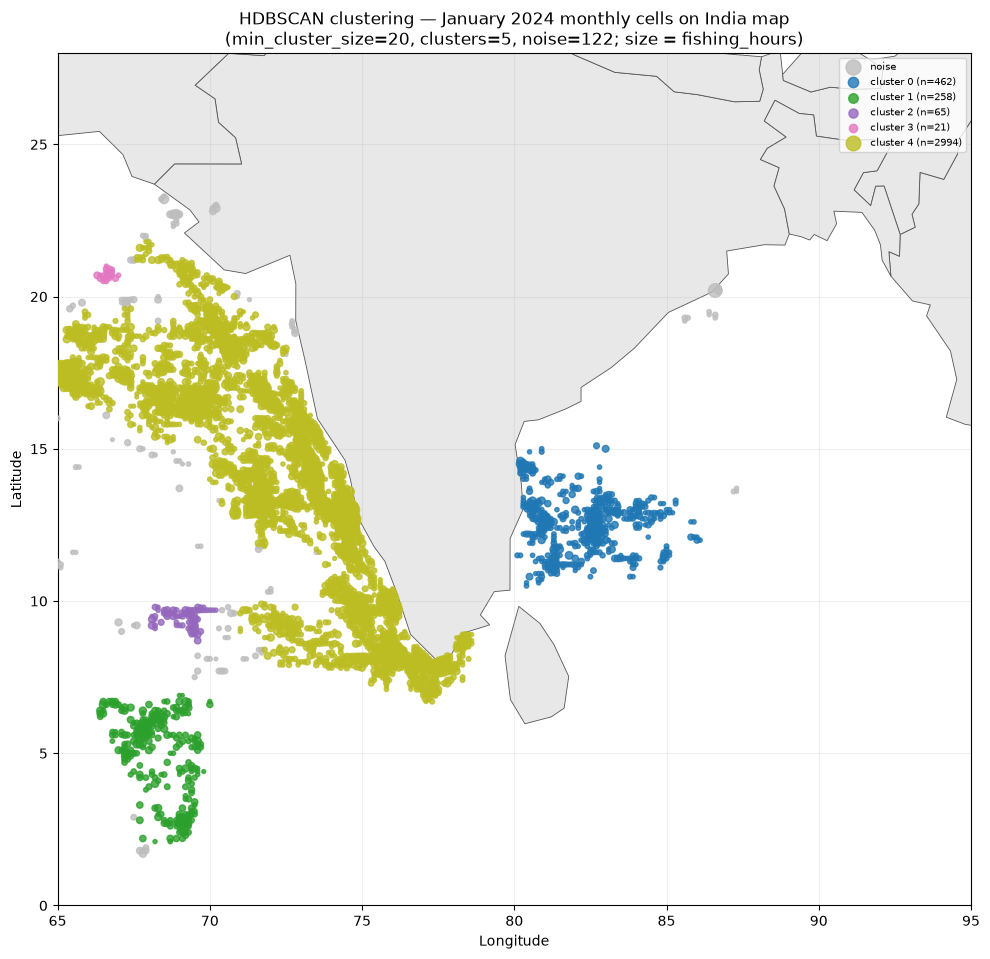

saved jan-2024 cluster table + figure


In [10]:
JAN_YEAR, JAN_MONTH, JAN_MCS = 2024, 1, 20
jan = pd.read_parquet(ANALYSIS_DIR / "monthly_cell.parquet")
jan = jan[(jan["year"] == JAN_YEAR) & (jan["month"] == JAN_MONTH)].copy()
print(f"jan {JAN_YEAR}-{JAN_MONTH:02d} rows (all): {len(jan)}")
jan = jan[jan["cell_ll_lon"].between(65, 95) & jan["cell_ll_lat"].between(0, 28)].copy()
print(f"in India window: {len(jan)}")
jan_mean = float(jan["cell_ll_lat"].mean())
jan_kx = float(np.cos(np.radians(jan_mean)) * 111.32)
X_jan = np.column_stack([jan["cell_ll_lon"].to_numpy() * jan_kx,
                         jan["cell_ll_lat"].to_numpy() * 110.57])
jan_lab = hdbscan.HDBSCAN(min_cluster_size=JAN_MCS).fit_predict(X_jan)
jan["hdbscan_cluster"] = jan_lab
jan_ncl = len(set(jan_lab)) - (1 if -1 in jan_lab else 0)
jan_noise = int((jan_lab == -1).sum())
print(f"clusters={jan_ncl}, noise={jan_noise}")

gj_jan = json.load(open(BASE_DIR / "outputs" / "geo" / "ne_110m_admin_0_countries.geojson", encoding="utf-8"))
WANT_JAN = {"India", "Pakistan", "Bangladesh", "Myanmar", "Sri Lanka", "Nepal", "Bhutan"}
coast_jan = []
for f in gj_jan["features"]:
    nm = f["properties"].get("ADMIN") or f["properties"].get("NAME")
    if nm in WANT_JAN:
        g = f["geometry"]
        polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
        for poly in polys:
            coast_jan.append(Polygon(poly[0], closed=True))
jan_sizes = 6 + 90 * np.sqrt(jan["fishing_hours"].to_numpy() / jan["fishing_hours"].max())

fig, ax = plt.subplots(figsize=(10, 10))
ax.add_collection(PatchCollection(coast_jan, facecolor="#e8e8e8", edgecolor="#555555", linewidths=0.6, zorder=1))
uniq_jan = sorted(set(jan_lab))
cmap_jan = plt.get_cmap("tab20", max(len(uniq_jan), 2))
for k in uniq_jan:
    mk = jan_lab == k
    ax.scatter(jan.loc[mk, "cell_ll_lon"], jan.loc[mk, "cell_ll_lat"],
               s=jan_sizes[mk], alpha=0.8,
               color="#bdbdbd" if k == -1 else cmap_jan(k % 20),
               label=f"noise" if k == -1 else f"cluster {k} (n={int(mk.sum())})", zorder=3)
ax.set_xlim(65, 95)
ax.set_ylim(0, 28)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"HDBSCAN clustering \u2014 January {JAN_YEAR} monthly cells on India map\n(min_cluster_size={JAN_MCS}, clusters={jan_ncl}, noise={jan_noise}; size = fishing_hours)")
ax.grid(alpha=0.2)
ax.legend(fontsize=7, loc="best", frameon=True, markerscale=1.5)
fig.tight_layout()
fig.savefig(FIG_DIR / f"nb04_hdbscan_jan{JAN_YEAR}_india_map.png", dpi=200, bbox_inches="tight")
plt.show()
jan.to_parquet(ANALYSIS_DIR / f"hdbscan_jan{JAN_YEAR}_clusters.parquet", index=False)
print("saved jan-2024 cluster table + figure")
